# Indiana Hourly Electricity Consumption — LSTM Forecasting

**Dataset**: 14 years of hourly electricity consumption (2005–2018) merged with hourly weather data.

**Target**: `aep_mw` — electricity consumption in megawatts.

**Inputs**: `Temp_C`, `Dew_Point_C`, `RH_percent`, `Pressure_kPa`, `Wind_Dir_deg`, `Wind_Speed_mps`, `Visibility_km`, `Precip_cm` + temporal features.

**Anti-overfitting measures**: dropout, recurrent dropout, early stopping, learning-rate scheduling, TimeSeriesSplit cross-validation.

## 1. Install / Import Dependencies

In [2]:
# Uncomment to install if running fresh
!pip install tensorflow scikit-learn pandas numpy matplotlib seaborn


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    LSTM, Dense, Dropout, BatchNormalization, Bidirectional
)
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f'TensorFlow version: {tf.__version__}')

TensorFlow version: 2.21.0


## 2. Load Data

In [5]:
# ── Update these paths to match your environment ──
ENERGY_PATH  = '../data/raw/Indiana_energy_consumption_2005-18.csv'
WEATHER_PATH = '../data/raw/Indiana_weather_2005_2018.csv'

energy  = pd.read_csv(ENERGY_PATH,  parse_dates=['datetime'])
weather = pd.read_csv(WEATHER_PATH, parse_dates=['datetime'])

print('Energy shape :', energy.shape)
print('Weather shape:', weather.shape)
print()
print(energy.head(3))
print()
print(weather.head(3))

Energy shape : (119067, 2)
Weather shape: (166560, 9)

             datetime   aep_mw
0 2005-01-01 00:00:00  12892.0
1 2005-12-31 01:00:00  14254.0
2 2005-12-31 02:00:00  13761.0

             datetime  Temp_C  Dew_Point_C  RH_percent  Pressure_kPa  \
0 2005-01-01 01:00:00    -5.0         -6.7        88.0          99.5   
1 2005-01-01 02:00:00    -6.1         -8.3        84.0          99.5   
2 2005-01-01 03:00:00    -7.8         -9.4        88.0          99.5   

   Wind_Dir_deg  Wind_Speed_mps  Visibility_km  Precip_cm  
0         340.0             5.7            6.4        8.0  
1         340.0             5.0           11.3        8.0  
2         340.0             4.5           11.3        8.0  


## 3. Merge & Clean

In [6]:
# Round both timestamps to the nearest hour before merging
energy['datetime']  = energy['datetime'].dt.round('h')
weather['datetime'] = weather['datetime'].dt.round('h')

df = pd.merge(energy, weather, on='datetime', how='inner')
df = df.sort_values('datetime').reset_index(drop=True)

print(f'Merged shape : {df.shape}')
print(f'Date range   : {df["datetime"].min()}  →  {df["datetime"].max()}')
print()
print('Missing values per column:')
print(df.isnull().sum())

Merged shape : (119066, 10)
Date range   : 2005-01-01 01:00:00  →  2018-08-03 00:00:00

Missing values per column:
datetime          0
aep_mw            0
Temp_C            0
Dew_Point_C       0
RH_percent        0
Pressure_kPa      0
Wind_Dir_deg      0
Wind_Speed_mps    0
Visibility_km     0
Precip_cm         0
dtype: int64


In [7]:
# Linear interpolation for small gaps; forward-fill residuals
df = df.interpolate(method='linear', limit=3).ffill().bfill()

# Sanity check
assert df.isnull().sum().sum() == 0, 'NaNs remain — check your data!'
print('No missing values after cleaning.')

No missing values after cleaning.


## 4. Feature Engineering

In [8]:
dt = df['datetime']

# Cyclical encoding of time features (sin / cos prevents discontinuity)
df['hour_sin']       = np.sin(2 * np.pi * dt.dt.hour        / 24)
df['hour_cos']       = np.cos(2 * np.pi * dt.dt.hour        / 24)
df['dayofweek_sin']  = np.sin(2 * np.pi * dt.dt.dayofweek   / 7)
df['dayofweek_cos']  = np.cos(2 * np.pi * dt.dt.dayofweek   / 7)
df['month_sin']      = np.sin(2 * np.pi * dt.dt.month       / 12)
df['month_cos']      = np.cos(2 * np.pi * dt.dt.month       / 12)
df['dayofyear_sin']  = np.sin(2 * np.pi * dt.dt.dayofyear   / 365)
df['dayofyear_cos']  = np.cos(2 * np.pi * dt.dt.dayofyear   / 365)

# Binary flags
df['is_weekend'] = (dt.dt.dayofweek >= 5).astype(int)
df['is_business_hour'] = ((dt.dt.hour >= 8) & (dt.dt.hour <= 18)
                          & (dt.dt.dayofweek < 5)).astype(int)

# Lag features (capture recent consumption patterns)
for lag in [1, 2, 3, 24, 48, 168]:        # 1h, 2h, 3h, 1day, 2day, 1week
    df[f'lag_{lag}h'] = df['aep_mw'].shift(lag)

# Rolling statistics on consumption (avoid data leakage: shift by 1 first)
for window in [24, 168]:                   # 1-day, 1-week rolling
    shifted = df['aep_mw'].shift(1)
    df[f'roll_mean_{window}h'] = shifted.rolling(window).mean()
    df[f'roll_std_{window}h']  = shifted.rolling(window).std()

# Temperature interaction
df['temp_rh_interaction'] = df['Temp_C'] * df['RH_percent']

# Drop rows with NaN created by lags/rolling
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

print(f'Shape after feature engineering: {df.shape}')
print(f'Features created: {[c for c in df.columns if c not in ["datetime", "aep_mw"]]}')

Shape after feature engineering: (118898, 31)
Features created: ['Temp_C', 'Dew_Point_C', 'RH_percent', 'Pressure_kPa', 'Wind_Dir_deg', 'Wind_Speed_mps', 'Visibility_km', 'Precip_cm', 'hour_sin', 'hour_cos', 'dayofweek_sin', 'dayofweek_cos', 'month_sin', 'month_cos', 'dayofyear_sin', 'dayofyear_cos', 'is_weekend', 'is_business_hour', 'lag_1h', 'lag_2h', 'lag_3h', 'lag_24h', 'lag_48h', 'lag_168h', 'roll_mean_24h', 'roll_std_24h', 'roll_mean_168h', 'roll_std_168h', 'temp_rh_interaction']


## 5. Exploratory Data Analysis

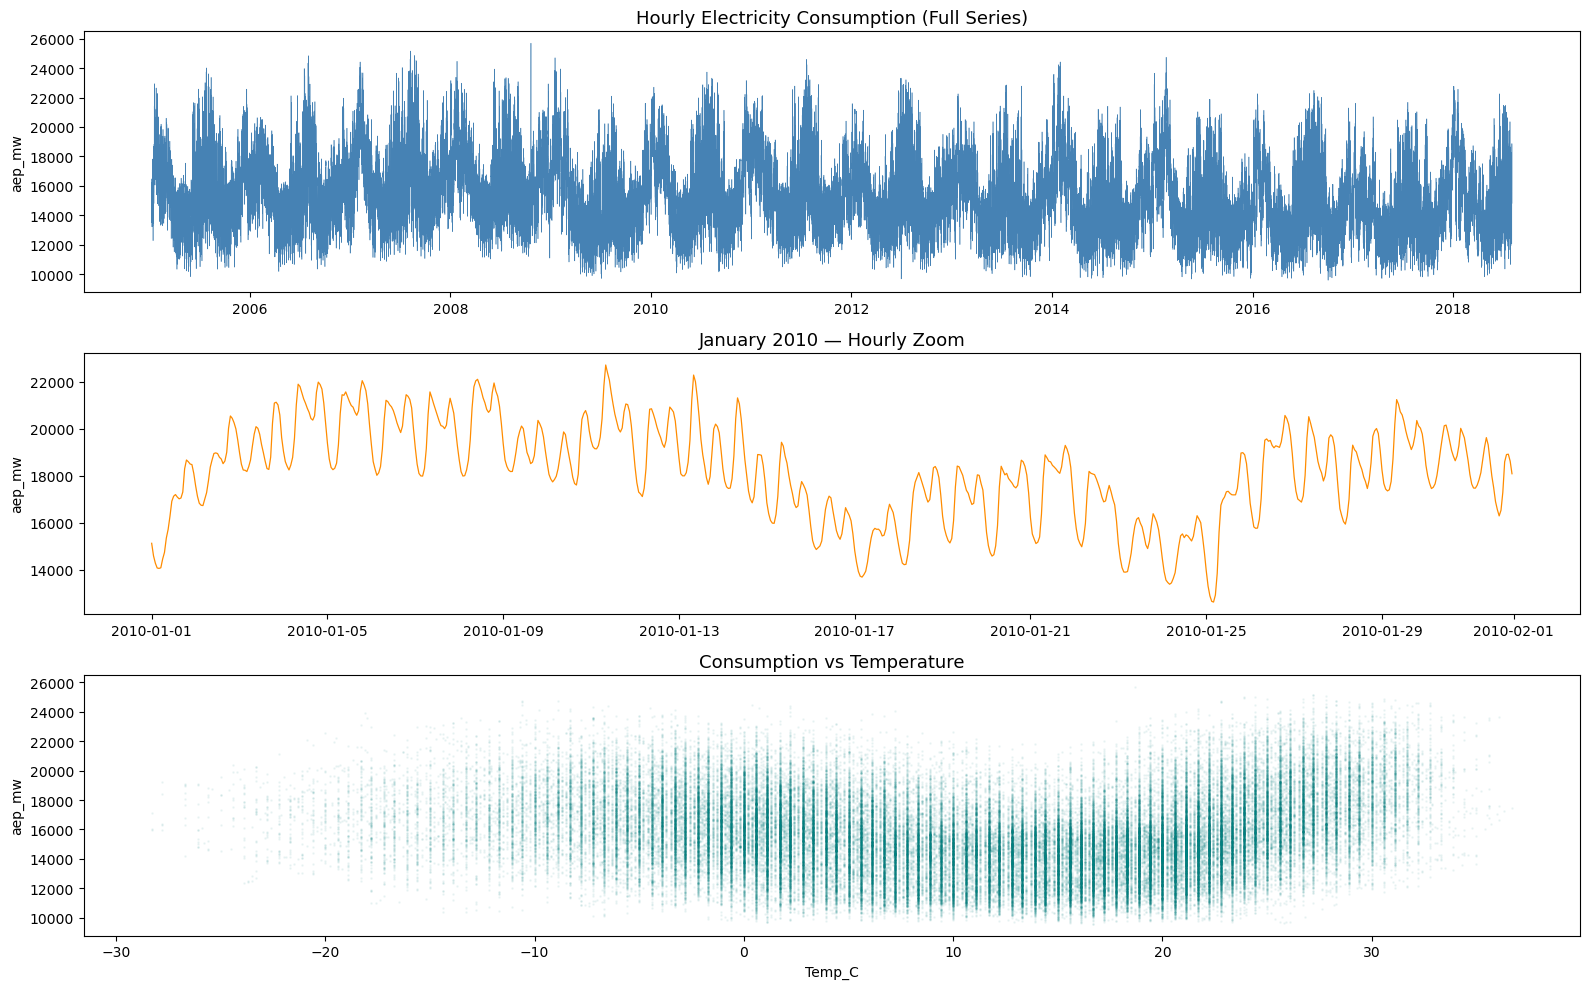

EDA plot saved.


In [9]:
fig, axes = plt.subplots(3, 1, figsize=(16, 10))

# Full series
axes[0].plot(df['datetime'], df['aep_mw'], linewidth=0.4, color='steelblue')
axes[0].set_title('Hourly Electricity Consumption (Full Series)', fontsize=13)
axes[0].set_ylabel('aep_mw')

# One month zoom
month_mask = (df['datetime'] >= '2010-01-01') & (df['datetime'] < '2010-02-01')
axes[1].plot(df.loc[month_mask, 'datetime'], df.loc[month_mask, 'aep_mw'],
             color='darkorange', linewidth=0.9)
axes[1].set_title('January 2010 — Hourly Zoom', fontsize=13)
axes[1].set_ylabel('aep_mw')

# Consumption vs Temperature
axes[2].scatter(df['Temp_C'], df['aep_mw'], alpha=0.05, s=1, color='teal')
axes[2].set_title('Consumption vs Temperature', fontsize=13)
axes[2].set_xlabel('Temp_C')
axes[2].set_ylabel('aep_mw')

plt.tight_layout()
plt.savefig('../outputs/figures/eda_overview.png', dpi=120, bbox_inches='tight')
plt.show()
print('EDA plot saved.')

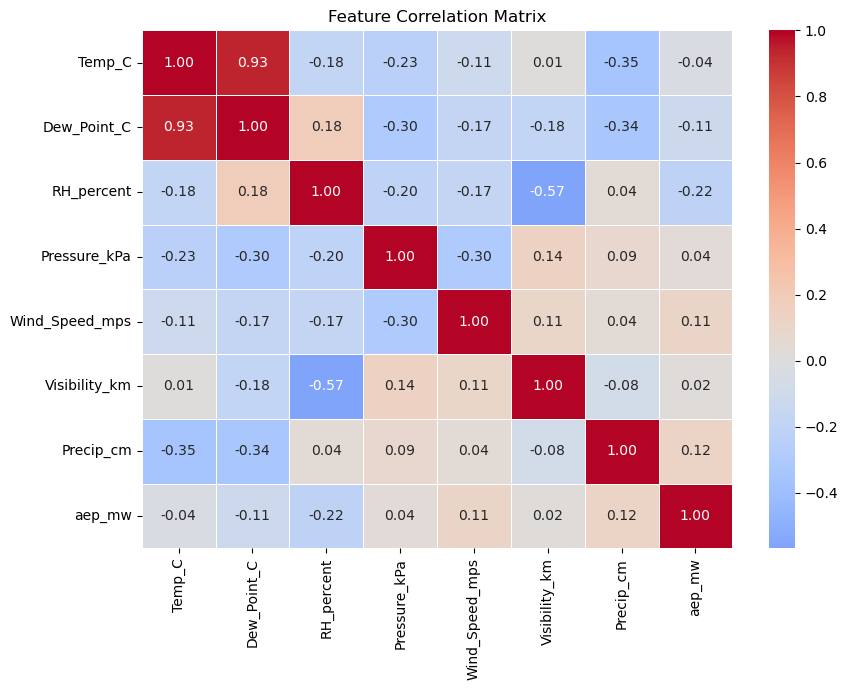

In [10]:
# Correlation heatmap
weather_cols = ['Temp_C','Dew_Point_C','RH_percent','Pressure_kPa',
                'Wind_Speed_mps','Visibility_km','Precip_cm','aep_mw']
plt.figure(figsize=(9, 7))
sns.heatmap(df[weather_cols].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.savefig('../outputs/figures/correlation_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

## 6. Train / Validation / Test Split

In [11]:
FEATURE_COLS = [
    'Temp_C', 'Dew_Point_C', 'RH_percent', 'Pressure_kPa',
    'Wind_Dir_deg', 'Wind_Speed_mps', 'Visibility_km', 'Precip_cm',
    'hour_sin', 'hour_cos', 'dayofweek_sin', 'dayofweek_cos',
    'month_sin', 'month_cos', 'dayofyear_sin', 'dayofyear_cos',
    'is_weekend', 'is_business_hour',
    'lag_1h', 'lag_2h', 'lag_3h', 'lag_24h', 'lag_48h', 'lag_168h',
    'roll_mean_24h', 'roll_std_24h',
    'roll_mean_168h', 'roll_std_168h',
    'temp_rh_interaction'
]
TARGET_COL = 'aep_mw'

# Chronological 70 / 10 / 20 split  (no random shuffle — time series!)
n = len(df)
train_end = int(n * 0.70)
val_end   = int(n * 0.80)

train_df = df.iloc[:train_end]
val_df   = df.iloc[train_end:val_end]
test_df  = df.iloc[val_end:]

print(f'Train : {len(train_df):,} rows  ({train_df["datetime"].min().date()} → {train_df["datetime"].max().date()})')
print(f'Val   : {len(val_df):,} rows  ({val_df["datetime"].min().date()}   → {val_df["datetime"].max().date()})')
print(f'Test  : {len(test_df):,} rows  ({test_df["datetime"].min().date()}  → {test_df["datetime"].max().date()})')

Train : 83,228 rows  (2005-01-08 → 2014-07-08)
Val   : 11,890 rows  (2014-07-08   → 2015-11-15)
Test  : 23,780 rows  (2015-11-15  → 2018-08-03)


## 7. Scaling
> **Important**: Fit the scaler ONLY on the training set to prevent data leakage.

In [12]:
feature_scaler = StandardScaler()
target_scaler  = StandardScaler()

X_train = feature_scaler.fit_transform(train_df[FEATURE_COLS])
X_val   = feature_scaler.transform(val_df[FEATURE_COLS])
X_test  = feature_scaler.transform(test_df[FEATURE_COLS])

y_train = target_scaler.fit_transform(train_df[[TARGET_COL]])
y_val   = target_scaler.transform(val_df[[TARGET_COL]])
y_test  = target_scaler.transform(test_df[[TARGET_COL]])

print('Scaling done — shapes:')
print(f'  X_train: {X_train.shape},  y_train: {y_train.shape}')
print(f'  X_val  : {X_val.shape},    y_val  : {y_val.shape}')
print(f'  X_test : {X_test.shape},   y_test : {y_test.shape}')

Scaling done — shapes:
  X_train: (83228, 29),  y_train: (83228, 1)
  X_val  : (11890, 29),    y_val  : (11890, 1)
  X_test : (23780, 29),   y_test : (23780, 1)


## 8. Sequence Generator
LSTM expects 3-D input `(samples, timesteps, features)`.

In [13]:
def create_sequences(X, y, seq_len: int):
    """Slide a window of `seq_len` hours over X to predict next-step y."""
    xs, ys = [], []
    for i in range(seq_len, len(X)):
        xs.append(X[i - seq_len : i])
        ys.append(y[i])
    return np.array(xs), np.array(ys)

# 168 hours = 1 week look-back is ideal for electricity demand
SEQ_LEN = 168

X_tr_seq, y_tr_seq = create_sequences(X_train, y_train, SEQ_LEN)
X_vl_seq, y_vl_seq = create_sequences(X_val,   y_val,   SEQ_LEN)
X_te_seq, y_te_seq = create_sequences(X_test,  y_test,  SEQ_LEN)

print('Sequence shapes:')
print(f'  Train : X={X_tr_seq.shape}, y={y_tr_seq.shape}')
print(f'  Val   : X={X_vl_seq.shape}, y={y_vl_seq.shape}')
print(f'  Test  : X={X_te_seq.shape}, y={y_te_seq.shape}')

MemoryError: Unable to allocate 3.02 GiB for an array with shape (83060, 168, 29) and data type float64

## 9. Build the LSTM Model

Architecture choices that prevent overfitting on 14-year data:
- **Bidirectional LSTM** — captures both past and near-future temporal context
- **Dropout + Recurrent Dropout** — regularise activations and recurrent weights
- **BatchNormalization** — stabilises and speeds training
- **L2 kernel regularization** — penalises large weights
- **Early Stopping** — halts when val_loss stops improving
- **ReduceLROnPlateau** — fine-tunes learning when plateauing

In [ ]:
N_FEATURES = X_tr_seq.shape[2]

def build_lstm(seq_len: int, n_features: int,
               units_1: int = 128,
               units_2: int = 64,
               dropout_rate: float = 0.3,
               recurrent_dropout: float = 0.2,
               l2_reg: float = 1e-4,
               lr: float = 1e-3) -> tf.keras.Model:

    model = Sequential([
        # Layer 1 — Bidirectional LSTM
        Bidirectional(
            LSTM(units_1,
                 return_sequences=True,
                 dropout=dropout_rate,
                 recurrent_dropout=recurrent_dropout,
                 kernel_regularizer=l2(l2_reg)),
            input_shape=(seq_len, n_features)
        ),
        BatchNormalization(),
        Dropout(dropout_rate),

        # Layer 2 — LSTM
        LSTM(units_2,
             return_sequences=False,
             dropout=dropout_rate,
             recurrent_dropout=recurrent_dropout,
             kernel_regularizer=l2(l2_reg)),
        BatchNormalization(),
        Dropout(dropout_rate),

        # Dense head
        Dense(32, activation='relu', kernel_regularizer=l2(l2_reg)),
        Dropout(0.1),
        Dense(1)   # regression output — no activation
    ])

    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss='huber',         # Huber loss is robust to outliers
        metrics=['mae']
    )
    return model


model = build_lstm(SEQ_LEN, N_FEATURES)
model.summary()

## 10. Callbacks

In [ ]:
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=10,           # wait 10 epochs before stopping
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,            # halve LR when val_loss plateaus
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    ModelCheckpoint(
        filepath='../models/best_lstm_model.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]
print('Callbacks configured.')

## 11. Train the Model

In [ ]:
BATCH_SIZE = 512   # Large batch → faster on big dataset, slightly regularising
EPOCHS     = 100   # EarlyStopping will terminate well before this

history = model.fit(
    X_tr_seq, y_tr_seq,
    validation_data=(X_vl_seq, y_vl_seq),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    shuffle=False,    # MUST be False for time-series data
    verbose=1
)

print('\nTraining complete.')

## 12. Training History — Overfitting Check

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(history.history['loss'],     label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Huber Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history.history['mae'],     label='Train MAE')
axes[1].plot(history.history['val_mae'], label='Val MAE')
axes[1].set_title('Mean Absolute Error')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.suptitle('Training History — Overfitting Diagnostic', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('../outputs/figures/training_history.png', dpi=120, bbox_inches='tight')
plt.show()

# If val_loss diverges significantly from train_loss → overfitting
final_train = history.history['loss'][-1]
final_val   = history.history['val_loss'][-1]
gap_ratio   = abs(final_val - final_train) / final_train
print(f'Final train loss : {final_train:.4f}')
print(f'Final val loss   : {final_val:.4f}')
print(f'Gap ratio        : {gap_ratio:.2%}  ← should be < 20% for healthy fit')

## 13. Evaluate on Test Set

In [ ]:
# Load best saved weights
model.load_weights('../models/best_lstm_model.keras')

y_pred_scaled = model.predict(X_te_seq, batch_size=BATCH_SIZE, verbose=0)

# Inverse transform back to MW
y_pred = target_scaler.inverse_transform(y_pred_scaled).flatten()
y_true = target_scaler.inverse_transform(y_te_seq).flatten()

mae   = mean_absolute_error(y_true, y_pred)
rmse  = np.sqrt(mean_squared_error(y_true, y_pred))
mape  = np.mean(np.abs((y_true - y_pred) / (y_true + 1e-8))) * 100
r2    = r2_score(y_true, y_pred)

print('═' * 45)
print('  TEST SET METRICS')
print('═' * 45)
print(f'  MAE  : {mae:>10,.2f} MW')
print(f'  RMSE : {rmse:>10,.2f} MW')
print(f'  MAPE : {mape:>10.2f} %')
print(f'  R²   : {r2:>10.4f}')
print('═' * 45)

## 14. Visualise Predictions

In [ ]:
# Align timestamps with the sequences (first SEQ_LEN rows are consumed by windowing)
test_dates = test_df['datetime'].values[SEQ_LEN:]

fig, axes = plt.subplots(2, 1, figsize=(16, 9))

# Full test period
axes[0].plot(test_dates, y_true, label='Actual',    linewidth=0.6, color='steelblue')
axes[0].plot(test_dates, y_pred, label='Predicted', linewidth=0.6,
             color='tomato', alpha=0.8)
axes[0].set_title('Actual vs Predicted — Full Test Period', fontsize=13)
axes[0].set_ylabel('MW')
axes[0].legend()

# 2-week zoom
ZOOM = 336   # 2 weeks of hours
axes[1].plot(test_dates[:ZOOM], y_true[:ZOOM], label='Actual',    linewidth=1.2, color='steelblue')
axes[1].plot(test_dates[:ZOOM], y_pred[:ZOOM], label='Predicted', linewidth=1.2,
             color='tomato', alpha=0.85)
axes[1].set_title('Actual vs Predicted — First 2 Weeks of Test Period', fontsize=13)
axes[1].set_ylabel('MW')
axes[1].legend()

plt.tight_layout()
plt.savefig('../outputs/figures/predictions.png', dpi=120, bbox_inches='tight')
plt.show()

In [ ]:
# Scatter: Actual vs Predicted
plt.figure(figsize=(7, 7))
plt.scatter(y_true, y_pred, alpha=0.15, s=2, color='teal')
lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
plt.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect prediction')
plt.xlabel('Actual (MW)')
plt.ylabel('Predicted (MW)')
plt.title(f'Actual vs Predicted — R² = {r2:.4f}')
plt.legend()
plt.tight_layout()
plt.savefig('../outputs/figures/scatter_actual_vs_pred.png', dpi=120, bbox_inches='tight')
plt.show()

## 15. Optional — TimeSeriesSplit Cross-Validation
Use this to get a statistically robust estimate of model generalisation. Expects a few minutes of compute on the full 14-year dataset.

In [ ]:
RUN_CV = False   # Set to True to run 5-fold time-series CV

if RUN_CV:
    tscv   = TimeSeriesSplit(n_splits=5)
    X_full = np.concatenate([X_tr_seq, X_vl_seq, X_te_seq], axis=0)
    y_full = np.concatenate([y_tr_seq, y_vl_seq, y_te_seq], axis=0)

    cv_scores = []
    for fold, (tr_idx, vl_idx) in enumerate(tscv.split(X_full), 1):
        print(f'\n--- Fold {fold} ---')
        m = build_lstm(SEQ_LEN, N_FEATURES)
        cb = [
            EarlyStopping(monitor='val_loss', patience=8,
                          restore_best_weights=True, verbose=0),
            ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                             patience=4, min_lr=1e-6, verbose=0)
        ]
        m.fit(X_full[tr_idx], y_full[tr_idx],
              validation_data=(X_full[vl_idx], y_full[vl_idx]),
              epochs=60, batch_size=BATCH_SIZE,
              callbacks=cb, shuffle=False, verbose=0)

        preds  = m.predict(X_full[vl_idx], batch_size=BATCH_SIZE, verbose=0)
        preds  = target_scaler.inverse_transform(preds).flatten()
        actual = target_scaler.inverse_transform(y_full[vl_idx]).flatten()
        fold_mae = mean_absolute_error(actual, preds)
        cv_scores.append(fold_mae)
        print(f'  Fold {fold} MAE: {fold_mae:,.2f} MW')

    print(f'\nCV MAE: {np.mean(cv_scores):,.2f} ± {np.std(cv_scores):,.2f} MW')

## 16. Save Artefacts

In [ ]:
import joblib

model.save('../models/indiana_lstm_final.keras')
joblib.dump(feature_scaler, '../models/feature_scaler.pkl')
joblib.dump(target_scaler,  '../models/target_scaler.pkl')

# Save test predictions for further analysis
results_df = pd.DataFrame({
    'datetime' : test_dates,
    'actual_mw': y_true,
    'pred_mw'  : y_pred,
    'error_mw' : y_true - y_pred
})
results_df.to_csv('../outputs/test_predictions.csv', index=False)

print('Saved:')
print('  indiana_lstm_final.keras')
print('  feature_scaler.pkl')
print('  target_scaler.pkl')
print('  test_predictions.csv')

---
## Model Architecture Summary

| Component | Detail |
|---|---|
| Architecture | Bidirectional LSTM → LSTM → Dense |
| Look-back window | 168 hours (1 week) |
| Loss function | Huber (robust to MW outliers) |
| Regularisation | Dropout (0.3), Recurrent Dropout (0.2), L2 (1e-4) |
| Batch Norm | After each LSTM layer |
| Optimiser | Adam with ReduceLROnPlateau |
| Overfitting guard | EarlyStopping (patience=10) + restore best weights |
| Data leakage guard | Scalers fit on train only; no shuffle in `model.fit` |
| Temporal features | Cyclical (sin/cos) encoding for hour, weekday, month |
| Lag features | 1h, 2h, 3h, 24h, 48h, 168h |
| Rolling features | 24h & 168h mean/std (shifted to avoid leakage) |